# Electric field cuts
Magnitude of the electric field along a segment through the device, at the last subhistory of the
Monte Carlo runs (`MC/deep_implant_<DI>/voltage_ramp-<V>V`).

The runs store the field as one constant vector per tetrahedron (cell data), so a direct cut is a
staircase. As ParaView's *Cell Data to Point Data*, the field is averaged on the mesh points first and then
interpolated linearly along the segment (*Plot Over Line*). Functions are in `field_cut.py`.

Figures are saved in `SAVE_DIR` as `.png`, `.pdf` and editable `.mplfig`
(reopen with `python open_fig.py <file>.mplfig` or `mcplot.load_figure`).

In [14]:
# Interactive figures (zoom/pan) need ipympl; otherwise fall back to static figures
try:
    import ipympl  # noqa: F401
    get_ipython().run_line_magic("matplotlib", "widget")
except ImportError:
    get_ipython().run_line_magic("matplotlib", "inline")
import os

import matplotlib.pyplot as plt
import numpy as np

from field_cut import field_magnitude_cut, last_snapshot
from mcplot import save_figure, set_style

set_style(28)

SAVE_FIGURES = True  # save every figure as .png, .pdf and editable .mplfig
SAVE_DIR = "output/efield_cuts"


def save(fig, name):
    """Save fig as SAVE_DIR/name.{png,pdf,mplfig} (reopen the .mplfig with open_fig.py)."""
    if SAVE_FIGURES:
        save_figure(fig, os.path.join(SAVE_DIR, name), formats=("png", "pdf"), dpi=300, bbox_inches="tight")

# Runs and cut

In [15]:
base_path = "/home/angelo/server/csmhome2/amudano/Projects/MC3D/DEMC/SPAD_FBK_v2/quasi_1D/MC"
runs = {  # deep implant (µm): bias (V); the last subhistory of each run is used
    "1.0": -36.0,
    "1.1": -38.0,
    "1.2": -41.0,
    "1.3": -43.0
}
cut_start = (0.5, 5.0, 0.5)  # x, y, z (µm)
cut_end = (0.5, 0.0, 0.5)
n_samples = 1000  # points along the cut

x_axis = "distance"  # abscissa: "distance" from cut_start (depth from y = 5 for the default cut),
#                     or the "x", "y" or "z" coordinate along the cut
x_label = "y (µm)"
normalize = True  # |E| divided by its maximum over all the plotted curves
label_fmt = "{di} µm, {v:g} V"  # legend label, can use {di} and {v} (e.g. "{di} µm, {v:g} V")
inset_xlim = (0.0, 1.42)  # abscissa range of the zoomed inset; None for no inset
inset_bounds = (0.35, 0.27, 0.63, 0.70)  # inset position: x0, y0, width, height (fraction of the axes)

In [16]:
cuts = {}  # label: (distance from cut_start (µm), |E| (V/m))
for di, v in runs.items():
    path, index = last_snapshot(f"{base_path}/deep_implant_{di}/voltage_ramp-{v:.2f}V")
    distance, e_mag = field_magnitude_cut(path, cut_start, cut_end, n_samples)
    cuts[label_fmt.format(di=di, v=v)] = (distance, e_mag)
    print(f"{di} µm, {v:g} V: subhistory {index}, max |E| on the cut = {np.nanmax(e_mag):.3e} V/m")

1.0 µm, -36 V: subhistory 2, max |E| on the cut = 4.114e+07 V/m
1.1 µm, -38 V: subhistory 2, max |E| on the cut = 3.885e+07 V/m
1.2 µm, -41 V: subhistory 2, max |E| on the cut = 3.841e+07 V/m
1.3 µm, -43 V: subhistory 2, max |E| on the cut = 3.718e+07 V/m


# Plot

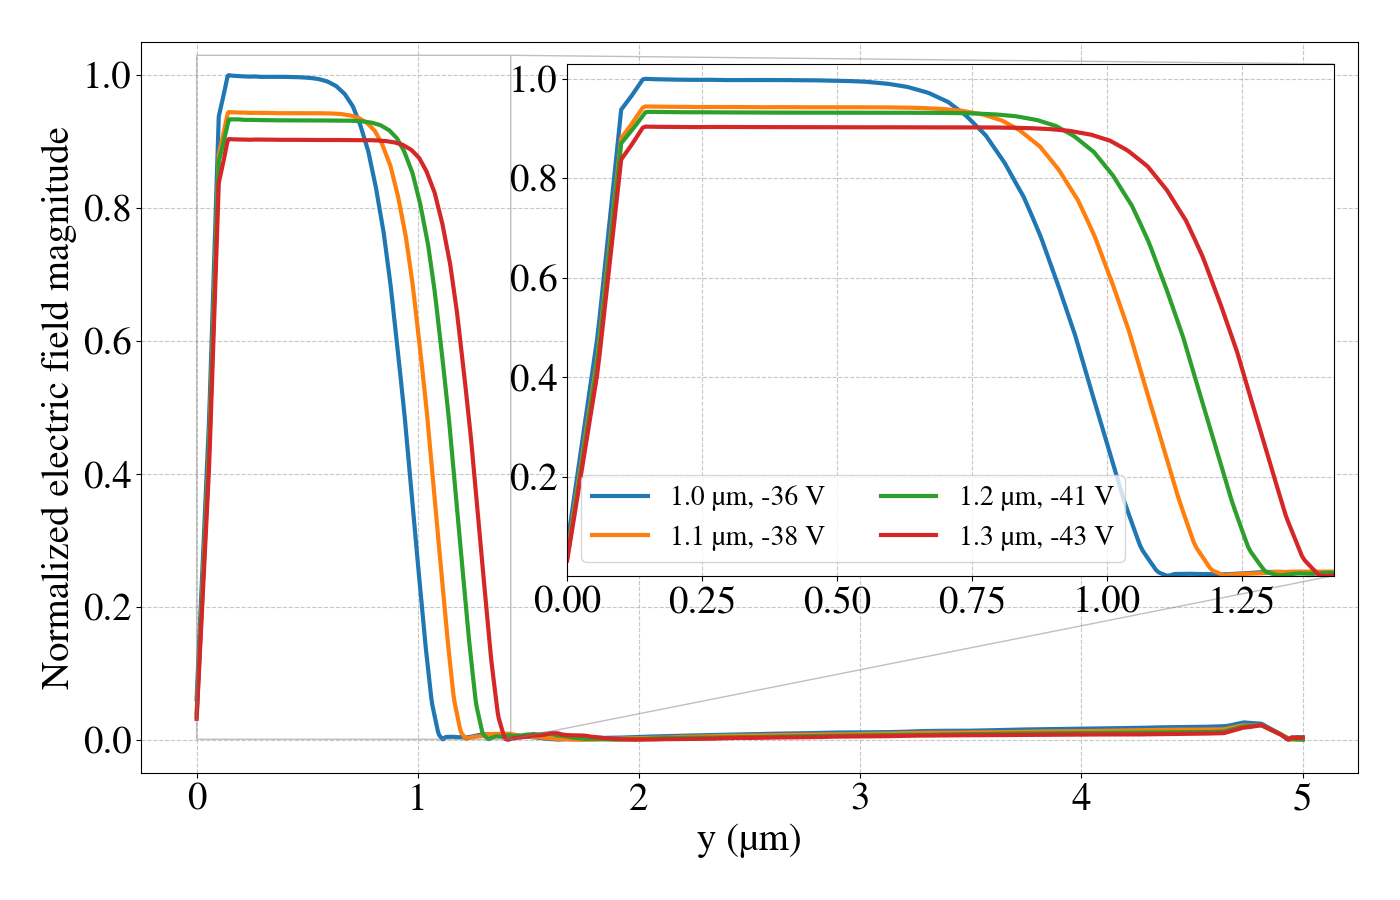

In [17]:
plt.close("all")


def abscissa(distance):
    """Distance from cut_start converted to the x_axis coordinate (µm)."""
    if x_axis == "distance":
        return distance
    k = "xyz".index(x_axis)
    length = np.linalg.norm(np.subtract(cut_end, cut_start))
    return cut_start[k] + distance / length * (cut_end[k] - cut_start[k])


scale = max(np.nanmax(e_mag) for _, e_mag in cuts.values()) if normalize else 1.0
fig, ax = plt.subplots(figsize=(14, 9))
axes = [ax]
if inset_xlim is not None:
    axins = ax.inset_axes(inset_bounds)
    axes.append(axins)
for axis in axes:
    for i, (label, (distance, e_mag)) in enumerate(cuts.items()):
        axis.plot(abscissa(distance), e_mag / scale, linewidth=3, color=f"C{i}", label=label)
    axis.grid(True, linestyle="--", alpha=0.7)

if inset_xlim is not None:
    in_range = [e_mag[(abscissa(d) >= min(inset_xlim)) & (abscissa(d) <= max(inset_xlim))] / scale
                for d, e_mag in cuts.values()]
    y_max = max(np.nanmax(e) for e in in_range if len(e))
    axins.set_xlim(inset_xlim)
    axins.set_ylim(0.001, 1.03 * y_max)
    ax.indicate_inset_zoom(axins, edgecolor="grey")
    axins.legend(ncol=min(len(cuts), 2), loc="lower left", fontsize=20)
else:
    ax.legend()
ax.set_xlabel(x_label)
ax.set_ylabel("Normalized electric field magnitude" if normalize else "Electric field magnitude, V/m")
fig.tight_layout()
save(fig, "efield_cut")
plt.show()